<a href="https://colab.research.google.com/github/RBorczuch/PlatesOCR/blob/main/PlatesOCR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/RBorczuch/PlatesOCR/blob/main/PlatesOCR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PlatesOCR: license plate recognition with a CRNN + CTC model

This notebook trains a network that reads the text of Polish license plates. It uses the [Poland vehicle license plate dataset](https://www.kaggle.com/datasets/piotrstefaskiue/poland-vehicle-license-plate-dataset) (290 photos from Katowice, annotated in CVAT with a box and the plate number for every plate).

1. **Dataset and plate extraction**: download the dataset, cut every plate out with a perspective transform and save it under its plate number.
2. **Model**: a CNN + bidirectional LSTM network trained with the CTC loss.
3. **Training and evaluation**: train the model, or load a model trained before.
4. **Inference**: read the text of plate crops.

See `README.md` for a full description of how it works.

## 0. Setup

In [1]:
import math
import re
import shutil
import sys
import xml.etree.ElementTree as ET
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import requests
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IN_COLAB = "google.colab" in sys.modules
BASE_DIR = Path("/content") if IN_COLAB else Path.cwd()

# Pipeline switches
RUN_EXTRACTION = True   # download the dataset (about 600 MB) and cut out the plates
RUN_TRAINING = True     # train the model; False loads MODEL_PATH

# Paths
DATASET_DIR = BASE_DIR / "dataset"            # unpacked Kaggle dataset (annotations.xml + photos)
LABELED_DIR = BASE_DIR / "plates_images"      # plate crops, file name = plate number
MODEL_PATH = BASE_DIR / "final_model.h5"
CHECKPOINT_PATH = BASE_DIR / "best_model.weights.h5"

# Public Kaggle download, no account needed
DATASET_URL = "https://www.kaggle.com/api/v1/datasets/download/piotrstefaskiue/poland-vehicle-license-plate-dataset"

# Image sizes
PLATE_WIDTH, PLATE_HEIGHT = 400, 100   # extracted plate crops
IMG_WIDTH, IMG_HEIGHT = 200, 50        # model input
BOX_MARGIN = 0.06                      # extra border around each box, as a fraction of the plate height

# Characters the model can output (Q does not occur in the dataset). A model is tied to this list:
# changing it changes the number of outputs, so the model must be trained again.
CHARACTERS = list("0123456789ABCDEFGHIJKLMNOPRSTUVWXYZ")

# Training
BATCH_SIZE = 16
EPOCHS = 300
EARLY_STOPPING_PATIENCE = 30
TRAIN_FRACTION = 0.8
SEED = 42

print("TensorFlow", tf.__version__, "| GPUs:", len(tf.config.list_physical_devices("GPU")))

TensorFlow 2.21.0 | GPUs: 1


## 1. Dataset and plate extraction

The dataset contains `annotations.xml` (CVAT 1.1 format) and the photos. Each annotation is a box around a plate, sometimes rotated, with the plate number as an attribute:

```xml
<image id="3" name="101.jpg" width="2284" height="1522">
  <box label="plate" xtl="1268.64" ytl="679.43" xbr="1631.55" ybr="790.41" rotation="3.70">
    <attribute name="plate number">STA0461C</attribute>
  </box>
</image>
```

For every box the notebook:

1. computes its four corners, applying the rotation (degrees, clockwise around the box centre) and a small margin, so that no character is cut off,
2. warps those corners to a flat `400 x 100` image with a perspective transform,
3. saves the crop to `plates_images/` as `<plate number>.jpg`. Spaces in plate numbers are removed, and a plate that appears in more than one photo gets a `__2`, `__3`, ... suffix.

`plates_images/` is rebuilt from scratch every time this section runs.

290 plates saved to /content/plates_images


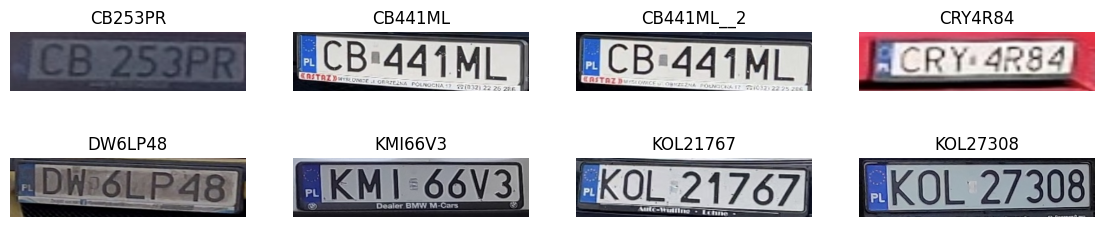

In [2]:
def download_and_extract(url, target_dir):
    """Download a zip archive from `url` and unpack it into `target_dir`."""
    target_dir.mkdir(parents=True, exist_ok=True)
    archive = target_dir / "download.zip"
    with requests.get(url, stream=True, timeout=60) as response:
        response.raise_for_status()
        with open(archive, "wb") as f:
            for chunk in response.iter_content(chunk_size=1 << 20):
                f.write(chunk)
    with zipfile.ZipFile(archive) as zf:
        zf.extractall(target_dir)
    archive.unlink()


def parse_cvat(xml_path):
    """Yield (photo name, plate number, box element) for every plate in a CVAT 1.1 XML file."""
    root = ET.parse(xml_path).getroot()
    for image in root.iter("image"):
        for box in image.iter("box"):
            text = next((a.text for a in box.iter("attribute") if a.get("name") == "plate number"), None)
            yield image.get("name"), text or "", box


def box_corners(box, margin=BOX_MARGIN):
    """Corners (TL, TR, BR, BL) of a CVAT box, rotated and enlarged by `margin` x height on every side."""
    xtl, ytl, xbr, ybr = (float(box.get(k)) for k in ("xtl", "ytl", "xbr", "ybr"))
    cx, cy = (xtl + xbr) / 2, (ytl + ybr) / 2
    half_h = (ybr - ytl) / 2
    half_w = (xbr - xtl) / 2 + 2 * margin * half_h
    half_h *= 1 + 2 * margin
    # CVAT rotation: degrees, clockwise around the centre (the image y axis points down)
    angle = math.radians(float(box.get("rotation", 0)))
    cos, sin = math.cos(angle), math.sin(angle)
    offsets = [(-half_w, -half_h), (half_w, -half_h), (half_w, half_h), (-half_w, half_h)]
    return np.float32([[cx + dx * cos - dy * sin, cy + dx * sin + dy * cos] for dx, dy in offsets])


PLATE_CORNERS = np.float32([
    [0, 0],
    [PLATE_WIDTH - 1, 0],
    [PLATE_WIDTH - 1, PLATE_HEIGHT - 1],
    [0, PLATE_HEIGHT - 1],
])


def warp_plate(image, corners):
    """Map the four plate corners onto a flat PLATE_WIDTH x PLATE_HEIGHT image."""
    matrix = cv2.getPerspectiveTransform(corners, PLATE_CORNERS)
    return cv2.warpPerspective(image, matrix, (PLATE_WIDTH, PLATE_HEIGHT))


def unique_path(directory, stem, suffix=".jpg"):
    """`directory/stem.jpg`, or `stem__2.jpg`, `stem__3.jpg`, ... if that name is taken."""
    path, n = directory / f"{stem}{suffix}", 1
    while path.exists():
        n += 1
        path = directory / f"{stem}__{n}{suffix}"
    return path


def extract_plates(dataset_dir, output_dir):
    """Cut every annotated plate out of the photos and save it under its plate number."""
    xml_path = next(dataset_dir.rglob("annotations.xml"))
    photos = {p.name: p for p in dataset_dir.rglob("*.jpg")}
    count, image_name, image = 0, None, None
    for name, text, box in parse_cvat(xml_path):
        label = re.sub(r"\s+", "", text).upper()
        if not label or name not in photos:
            print(f"Skipping a plate in {name}: no plate number or no photo")
            continue
        if name != image_name:
            image_name, image = name, cv2.imread(str(photos[name]))
        if image is None:
            print(f"Cannot read {photos[name]}")
            continue
        cv2.imwrite(str(unique_path(output_dir, label)), warp_plate(image, box_corners(box)))
        count += 1
    return count


if RUN_EXTRACTION:
    if not any(DATASET_DIR.rglob("annotations.xml")):
        print("Downloading the dataset...")
        download_and_extract(DATASET_URL, DATASET_DIR)
    shutil.rmtree(LABELED_DIR, ignore_errors=True)
    LABELED_DIR.mkdir(parents=True)
    print(f"{extract_plates(DATASET_DIR, LABELED_DIR)} plates saved to {LABELED_DIR}")

if LABELED_DIR.is_dir():
    examples = sorted(LABELED_DIR.glob("*.jpg"))[:8]
    _, ax = plt.subplots(2, 4, figsize=(14, 3))
    for a in ax.ravel():
        a.axis("off")
    for i, path in enumerate(examples):
        ax[i // 4, i % 4].imshow(cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB))
        ax[i // 4, i % 4].set_title(path.stem)
    plt.show()

## 2. Model

**Input encoding.** Every plate crop is converted to grayscale, scaled to `[0, 1]`, resized to `200 x 50` and transposed to `(width, height, 1)`, so that the first axis runs from the left edge of the plate to the right edge. The RNN treats that axis as time. There is no other preprocessing: the network learns to cope with dirt, glare and shadows from the data.

**Labels.** Characters are mapped to integers with `StringLookup` (index 0 is the `[UNK]` token). Plates have different lengths, so labels are padded with 0 within a batch and the CTC loss ignores the padding.

**Architecture.** Two convolution + max-pooling blocks extract features and shrink the image 4 times (`200 x 50` to `50 x 12`). Each of the 50 columns becomes one time step with 768 features, followed by a dense layer and two bidirectional LSTM layers. The output layer gives, for every time step, a probability for each character plus the CTC *blank*.

**CTC.** Connectionist Temporal Classification lets the network learn from the plate text alone, without the position of each character. `CTCLayer` adds the CTC loss during training and passes the predictions through unchanged. To read a plate, the most likely class is taken at every time step, repeated classes are merged and blanks are removed (greedy decoding).

`prediction_model` shares its layers with the training model and leaves out the label input and the loss.

In [3]:
char_to_num = layers.StringLookup(vocabulary=CHARACTERS, mask_token=None)
num_to_char = layers.StringLookup(vocabulary=char_to_num.get_vocabulary(), mask_token=None, invert=True)
NUM_CLASSES = len(char_to_num.get_vocabulary()) + 1  # + CTC blank (the last class)


def to_model_input(image):
    """uint8 grayscale image (H, W, 1) -> float32 tensor (IMG_WIDTH, IMG_HEIGHT, 1)."""
    image = tf.image.convert_image_dtype(image, tf.float32)
    image = tf.image.resize(image, [IMG_HEIGHT, IMG_WIDTH])
    # Transpose so that the first axis (the RNN time steps) runs along the plate width
    return tf.transpose(image, perm=[1, 0, 2])


def labels_to_text(indices):
    """Index sequence -> text, skipping label padding (0) and decoder padding (-1)."""
    indices = tf.boolean_mask(indices, indices > 0)
    return tf.strings.reduce_join(num_to_char(indices)).numpy().decode("utf-8")


class CTCLayer(layers.Layer):
    """Adds the CTC loss during training and returns the predictions unchanged."""

    def __init__(self, **kwargs):
        # **kwargs lets Keras pass name/dtype/trainable when it rebuilds the layer
        super().__init__(**kwargs)

    def call(self, y_true, y_pred):
        y_true = tf.cast(y_true, tf.int32)
        label_length = tf.math.count_nonzero(y_true, axis=1, dtype=tf.int32)  # without the 0 padding
        logit_length = tf.fill([tf.shape(y_pred)[0]], tf.shape(y_pred)[1])
        loss = tf.nn.ctc_loss(
            labels=y_true,
            logits=tf.math.log(y_pred + 1e-7),
            label_length=label_length,
            logit_length=logit_length,
            logits_time_major=False,
            blank_index=-1,  # the last output class is the CTC blank
        )
        self.add_loss(tf.reduce_mean(loss))
        return y_pred


def build_model():
    """CRNN for plate reading: CNN features -> bidirectional LSTMs -> per-step character probabilities."""
    input_img = layers.Input(shape=(IMG_WIDTH, IMG_HEIGHT, 1), name="image", dtype="float32")
    labels = layers.Input(shape=(None,), name="label", dtype="float32")

    # Two conv blocks; each max pooling halves both sides: (200, 50) -> (100, 25) -> (50, 12)
    x = layers.Conv2D(32, (3, 3), activation="relu", kernel_initializer="he_normal", padding="same", name="Conv1")(input_img)
    x = layers.MaxPooling2D((2, 2), name="pool1")(x)
    x = layers.Conv2D(64, (3, 3), activation="relu", kernel_initializer="he_normal", padding="same", name="Conv2")(x)
    x = layers.MaxPooling2D((2, 2), name="pool2")(x)

    # One time step per column: (50, 12, 64) -> (50, 768)
    x = layers.Reshape(target_shape=(IMG_WIDTH // 4, (IMG_HEIGHT // 4) * 64), name="reshape")(x)
    x = layers.Dense(64, activation="relu", name="dense1")(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True, dropout=0.25))(x)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True, dropout=0.25))(x)

    # Probability of every character + blank at each of the 50 time steps
    x = layers.Dense(NUM_CLASSES, activation="softmax", name="dense2")(x)
    output = CTCLayer(name="ctc_loss")(labels, x)

    model = keras.models.Model(inputs=[input_img, labels], outputs=output, name="ocr_model_v1")
    model.compile(optimizer=keras.optimizers.Adam())
    return model


def decode_predictions(pred):
    """Greedy CTC decoding: best class per time step, merge repeats, drop blanks."""
    pred = tf.convert_to_tensor(pred)
    sequence_length = tf.fill([tf.shape(pred)[0]], tf.shape(pred)[1])
    decoded, _ = tf.nn.ctc_greedy_decoder(
        tf.transpose(tf.math.log(pred + 1e-7), perm=[1, 0, 2]),  # expects (time, batch, classes)
        sequence_length=sequence_length,
    )
    results = tf.sparse.to_dense(decoded[0], default_value=-1)
    return [labels_to_text(r) for r in results]


model = build_model()
prediction_model = keras.models.Model(
    model.get_layer("image").output, model.get_layer("dense2").output, name="ocr_prediction_model"
)
model.summary()

Model: "ocr_model_v1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 200, 50,   │          0 │ -                 │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 200, 50,   │        320 │ image[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 100, 25,   │          0 │ Conv1[0][0]       │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv2 (Conv2D)      │ (None, 100, 25,   │     18,496 │ pool1[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool2               │ (None, 50, 12,    │          0 │ Conv2[0][0]       │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 50, 768)   │          0 │ pool2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense1 (Dense)      │ (None, 50, 64)    │     49,216 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 50, 64)    │          0 │ dense1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 50, 256)   │    197,632 │ dropout[0][0]     │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 50, 128)   │    164,352 │ bidirectional[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ label (InputLayer)  │ (None, None)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense2 (Dense)      │ (None, 50, 37)    │      4,773 │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ctc_loss (CTCLayer) │ (None, 50, 37)    │          0 │ label[0][0],      │
│                     │                   │            │ dense2[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 434,789 (1.66 MB)

 Trainable params: 434,789 (1.66 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Training

The label of each image in `plates_images/` is its file name. Images whose label contains a character outside `CHARACTERS` are skipped.

**Split by plate number.** Some cars appear in several photos. All crops of one plate number go to the same subset (80% of the plate numbers for training, 20% for validation); otherwise the validation set would contain plates the model has already seen, and the accuracy would look better than it is.

**Augmentation.** With fewer than 300 plates the network easily memorizes the training set. Every training image is therefore slightly changed each epoch: random shift by a few pixels, brightness, contrast and noise.

Training runs for up to 300 epochs and stops early after 30 epochs without improvement of `val_loss`. The best weights are saved to `best_model.weights.h5` during training and the final model to `final_model.h5`. With `RUN_TRAINING = False` the model is loaded from `final_model.h5` instead.

Training: 231 images, validation: 59 images


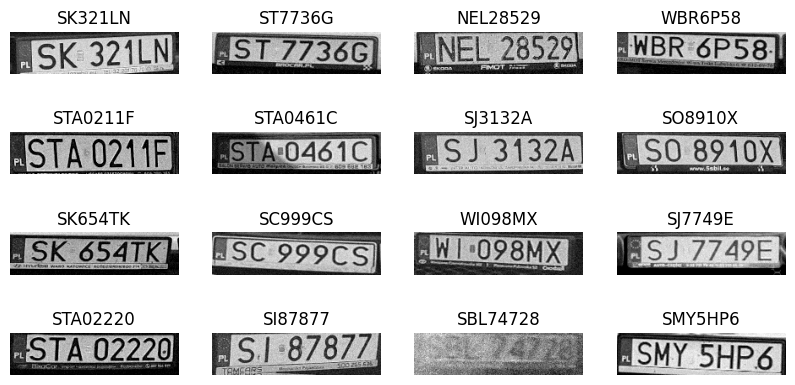

In [4]:
def label_from_path(path):
    """Plate number from a file name: 'SK404XK__2.jpg' -> 'SK404XK'."""
    return Path(path).stem.split("__")[0].replace("_", "").replace(" ", "").upper()


def split_by_plate(samples, train_fraction=TRAIN_FRACTION, seed=SEED):
    """Split (path, label) pairs so that all crops of one plate number end up in the same subset."""
    plates = sorted({label for _, label in samples})
    np.random.default_rng(seed).shuffle(plates)
    train_plates = set(plates[:round(len(plates) * train_fraction)])
    train = [s for s in samples if s[1] in train_plates]
    valid = [s for s in samples if s[1] not in train_plates]
    return train, valid


def encode_sample(image_path, label):
    """Dataset element: image file + label text -> model inputs."""
    image = tf.io.decode_jpeg(tf.io.read_file(image_path), channels=1)
    label = char_to_num(tf.strings.unicode_split(label, input_encoding="UTF-8"))
    return {"image": to_model_input(image), "label": label}


def augment(sample):
    """Random shift, brightness, contrast and noise for a training image."""
    image = tf.pad(sample["image"], [[6, 6], [3, 3], [0, 0]], mode="SYMMETRIC")
    image = tf.image.random_crop(image, [IMG_WIDTH, IMG_HEIGHT, 1])
    image = tf.image.random_brightness(image, 0.15)
    image = tf.image.random_contrast(image, 0.7, 1.3)
    image += tf.random.normal(tf.shape(image), stddev=0.03)
    return {"image": tf.clip_by_value(image, 0.0, 1.0), "label": sample["label"]}


def make_dataset(samples, training=False):
    paths, labels = zip(*samples)
    dataset = tf.data.Dataset.from_tensor_slices((list(paths), list(labels)))
    if training:
        dataset = dataset.shuffle(len(samples), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(encode_sample, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        dataset = dataset.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return (
        # Labels have different lengths: pad them with 0 ([UNK], never a real character)
        dataset.padded_batch(BATCH_SIZE, padding_values={"image": 0.0, "label": tf.constant(0, dtype=tf.int64)})
        .prefetch(tf.data.AUTOTUNE)
    )


if RUN_TRAINING:
    vocabulary = set(CHARACTERS)
    samples = []
    for path in sorted(LABELED_DIR.glob("*.jpg")):
        label = label_from_path(path)
        if label and set(label) <= vocabulary:
            samples.append((str(path), label))
        else:
            print(f"Skipping {path.name}: label {label!r} contains characters outside CHARACTERS")
    if len(samples) < 2:
        raise FileNotFoundError(f"Not enough plate images in {LABELED_DIR}, run section 1 first.")

    train_samples, valid_samples = split_by_plate(samples)
    train_dataset = make_dataset(train_samples, training=True)
    validation_dataset = make_dataset(valid_samples)
    print(f"Training: {len(train_samples)} images, validation: {len(valid_samples)} images")

    # Sample of the augmented training data, as the model sees it
    _, ax = plt.subplots(4, 4, figsize=(10, 5))
    for a in ax.ravel():
        a.axis("off")
    for batch in train_dataset.take(1):
        for i in range(min(16, len(batch["image"]))):
            ax[i // 4, i % 4].imshow(batch["image"][i, :, :, 0].numpy().T, cmap="gray")
            ax[i // 4, i % 4].set_title(labels_to_text(batch["label"][i]))
    plt.show()

Epoch 1/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 13s 232ms/step - loss: 55.6258 - val_loss: 30.1562
Epoch 2/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 198ms/step - loss: 26.7032 - val_loss: 25.3572
Epoch 3/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step - loss: 25.0687 - val_loss: 24.6506
Epoch 4/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 140ms/step - loss: 24.3972 - val_loss: 23.9774
Epoch 5/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 135ms/step - loss: 23.7630 - val_loss: 23.1857
Epoch 6/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 138ms/step - loss: 23.2533 - val_loss: 22.7538
Epoch 7/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 156ms/step - loss: 22.8628 - val_loss: 22.4696
Epoch 8/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 196ms/step - loss: 22.6740 - val_loss: 22.2500
Epoch 9/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step - loss: 22.4399 - val_loss: 22.0730
Epoch 10/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 138ms/step - loss: 22.2658 - val_loss: 21.8623
Epoch 11/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 134ms/step - loss: 22.1578 - val_loss: 21.7577
Epoch 12/300
15/15

Model saved to /content/final_model.h5


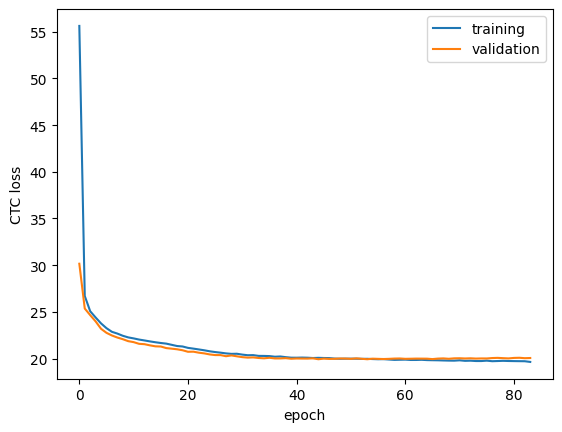

In [5]:
if RUN_TRAINING:
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True),
        # Keras 3 requires the .weights.h5 extension when saving weights only
        keras.callbacks.ModelCheckpoint(str(CHECKPOINT_PATH), monitor="val_loss", save_best_only=True, save_weights_only=True),
    ]
    history = model.fit(train_dataset, validation_data=validation_dataset, epochs=EPOCHS, callbacks=callbacks)

    # Best weights, also when training ran all epochs without stopping early
    if CHECKPOINT_PATH.exists():
        model.load_weights(str(CHECKPOINT_PATH))
    model.save(str(MODEL_PATH))
    print(f"Model saved to {MODEL_PATH}")

    plt.plot(history.history["loss"], label="training")
    plt.plot(history.history["val_loss"], label="validation")
    plt.xlabel("epoch")
    plt.ylabel("CTC loss")
    plt.legend()
    plt.show()
else:
    # load_weights instead of load_model: rebuilding the custom CTCLayer from an .h5 file
    # is not portable between Keras 2 and Keras 3, while the weights load into the same architecture.
    try:
        model.load_weights(str(MODEL_PATH))
    except ValueError as e:
        raise RuntimeError(
            f"{MODEL_PATH} does not fit the current model, probably because it was trained with a "
            "different CHARACTERS list. Train a new model with RUN_TRAINING = True."
        ) from e
    print(f"Weights loaded from {MODEL_PATH}")

### Evaluation

Predictions on the validation set, and two measures of quality:

- **plate accuracy**: share of plates read without a single mistake,
- **character error rate (CER)**: number of character edits (insertions, deletions, substitutions) needed to turn the predictions into the true plate numbers, divided by the number of true characters.

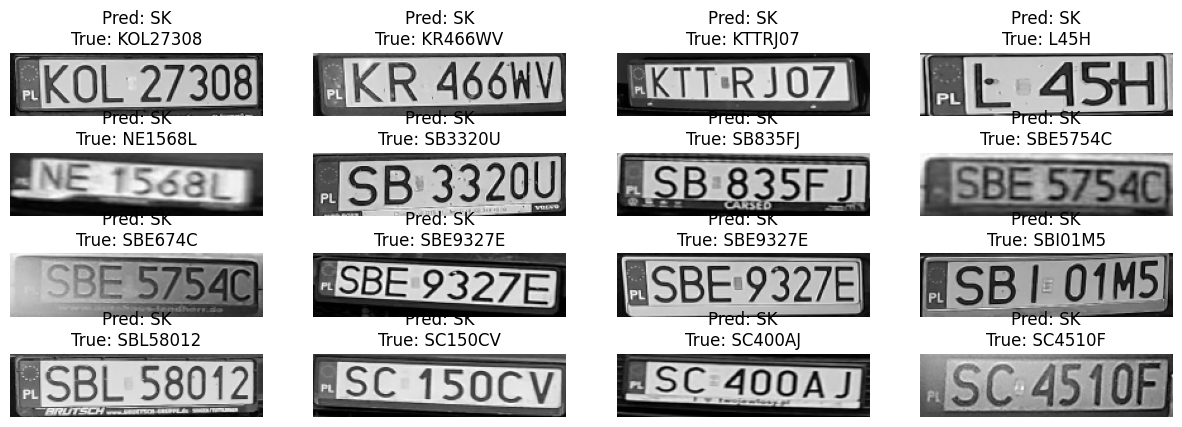

Plate accuracy: 0/59 = 0.0%
Character error rate: 83.9%


In [6]:
def edit_distance(a, b):
    """Levenshtein distance between two strings."""
    row = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, row[0] = row[0], i
        for j, cb in enumerate(b, 1):
            current = min(row[j] + 1, row[j - 1] + 1, prev + (ca != cb))
            prev, row[j] = row[j], current
    return row[-1]


if RUN_TRAINING:
    _, ax = plt.subplots(4, 4, figsize=(15, 5))
    for a in ax.ravel():
        a.axis("off")
    for batch in validation_dataset.take(1):
        pred_texts = decode_predictions(prediction_model.predict(batch["image"], verbose=0))
        for i in range(min(16, len(pred_texts))):
            ax[i // 4, i % 4].imshow(batch["image"][i, :, :, 0].numpy().T, cmap="gray")
            ax[i // 4, i % 4].set_title(f"Pred: {pred_texts[i]}\nTrue: {labels_to_text(batch['label'][i])}")
    plt.show()

    correct = errors = characters = 0
    for batch in validation_dataset:
        pred_texts = decode_predictions(prediction_model.predict(batch["image"], verbose=0))
        true_texts = [labels_to_text(label) for label in batch["label"]]
        correct += sum(p == t for p, t in zip(pred_texts, true_texts))
        errors += sum(edit_distance(p, t) for p, t in zip(pred_texts, true_texts))
        characters += sum(len(t) for t in true_texts)
    print(f"Plate accuracy: {correct}/{len(valid_samples)} = {correct / len(valid_samples):.1%}")
    print(f"Character error rate: {errors / characters:.1%}")

## 4. Inference

`read_plates` takes BGR plate crops (straightened like the ones in section 1, for example cut out with `warp_plate`) and returns the decoded text. The example reads a few validation crops, which the model did not train on.

KOL27308.jpg: SK
KR466WV.jpg: SK
KTTRJ07.jpg: SK
L45H.jpg: SK
NE1568L.jpg: SK
SB3320U.jpg: SK
SB835FJ.jpg: SK
SBE5754C.jpg: SK


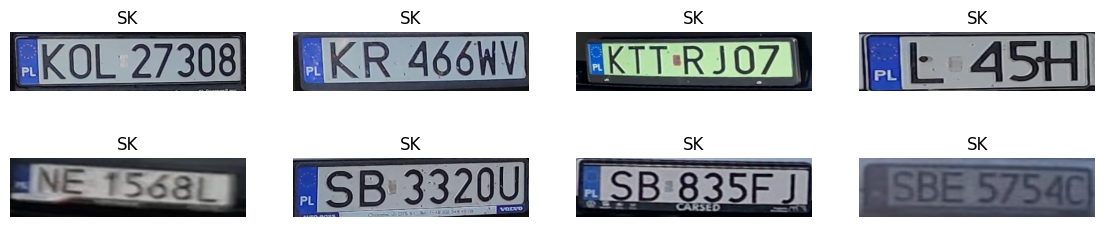

In [7]:
def read_plates(images):
    """Read the plate numbers of BGR plate crops."""
    batch = tf.stack([to_model_input(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)[..., np.newaxis]) for image in images])
    return decode_predictions(prediction_model.predict(batch, verbose=0))


if RUN_TRAINING:
    crop_paths = [Path(p) for p, _ in valid_samples[:8]]
else:
    crop_paths = sorted(LABELED_DIR.glob("*.jpg"))[:8] if LABELED_DIR.is_dir() else []

if crop_paths:
    crops = [cv2.imread(str(p)) for p in crop_paths]
    texts = read_plates(crops)
    _, ax = plt.subplots(2, 4, figsize=(14, 3))
    for a in ax.ravel():
        a.axis("off")
    for i, (path, crop, text) in enumerate(zip(crop_paths, crops, texts)):
        print(f"{path.name}: {text}")
        ax[i // 4, i % 4].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        ax[i // 4, i % 4].set_title(text)
    plt.show()